# <center>Fisher forecast for HM</center>
### <center>By Junsong Cang</center>


Set up required packages

In [1]:
import numpy as np
import sys, platform, tqdm, getdist, corner, h5py
import matplotlib.patches as mpatches
from matplotlib.colors import LogNorm
import matplotlib.pyplot as plt
import PyLab as PL
from getdist import plots
if platform.system() == 'Darwin':
    sys.path.insert(1, '/Users/cangtao/FileVault/GitHub/ResearchArchive/Hongmeng_SDM_2025_AA_SSPMA/ToolKit/')
else:
    sys.path.insert(1, '/afs/ihep.ac.cn/users/z/zhangzixuan/work/cjs/SDM_lite/ToolKit/')
from Fisher_ToolKit import Compute_Fisher_Matrix
plt.rcParams.update({
    'text.usetex': True,
    'font.family':'Times',
    'text.latex.preamble': r'\usepackage{newtxtext,newtxmath}'})
%matplotlib inline
%load_ext autoreload
%autoreload 2
%matplotlib widget

# Compute and plot limits

Compute Limits

In [2]:
block_sun = 1
mx_ax = np.linspace(-4, 3, 15)

params_exclude = ['fst', 'fesc', 'LX', 'ast', 'fst3', 'fesc3', 'LX3', 'ast3', 'aesc', 'E0', 'ALW']
params_exclude = ['fst', 'fesc', 'LX', 'ast', 'aesc', 'E0']
params_exclude = ['ast', 'ast3', 'E0', 'ALW', 'aesc']
params_exclude = ['FG0', 'FG1', 'FG2', 'FG3', 'FG4', 'ast', 'ast3', 'E0', 'ALW', 'aesc']
params_exclude = ['fst', 'fesc', 'LX', 'E0']
params_exclude = ['fesc', 'fesc3', 'aesc']
params_exclude = ['fst3', 'fesc3', 'LX3', 'ast3', 'ALW']
# params_exclude = ['fst', 'fesc', 'LX', 'ast', 'ALW']
params_exclude = ['FG0', 'FG1', 'FG2', 'FG3', 'FG4', 'ALW', 'E0', 'aesc']

nm = len(mx_ax)
Tobs = [1/12, 1, 5]
nt = len(Tobs)
sx = np.zeros([nt, nm])
sx_lite = np.zeros([nt, nm])
sx_II = np.zeros([nt, nm])
sx_III = np.zeros([nt, nm])

for mid in tqdm.tqdm(range(nm), desc = 'Computing SDM Limits'):
    for tid in [0, 1, 2]:
        T = Tobs[tid]
        # main results
        sx[tid, mid] = Compute_Fisher_Matrix(
            mx = mx_ax[mid],
            Tobs = T,
            NFG = 5,
            block_sun = block_sun,
            params_to_exclude = ['ALW', 'E0', 'aesc'])['sx42_limit']
        '''
        # exclude some params for test
        sx_lite[tid, mid] = Compute_Fisher_Matrix(
            mx = mx_ax[mid],
            Tobs = T,
            NFG = 5,
            block_sun = block_sun,
            params_to_exclude = params_exclude)['sx42_limit']
        # Pop III onlly
        '''
        sx_III[tid, mid] = Compute_Fisher_Matrix(
            mx = mx_ax[mid],
            Tobs = T,
            NFG = 5,
            block_sun = block_sun,
            params_to_exclude = ['ALW', 'E0', 'aesc', 'fst', 'fesc', 'LX', 'ast'])['sx42_limit']
        # Pop II only
        sx_II[tid, mid] = Compute_Fisher_Matrix(
            mx = mx_ax[mid],
            Tobs = T,
            NFG = 5,
            block_sun = block_sun,
            params_to_exclude = ['ALW', 'E0', 'aesc', 'fst3', 'fesc3', 'LX3', 'ast3'])['sx42_limit']
        
sx = sx * 1E-42
sx_lite = sx_lite * 1E-42
sx_II = sx_II * 1E-42
sx_III = sx_III * 1E-42

Computing SDM Limits: 100%|██████████| 15/15 [00:13<00:00,  1.15it/s]


Plot Limits

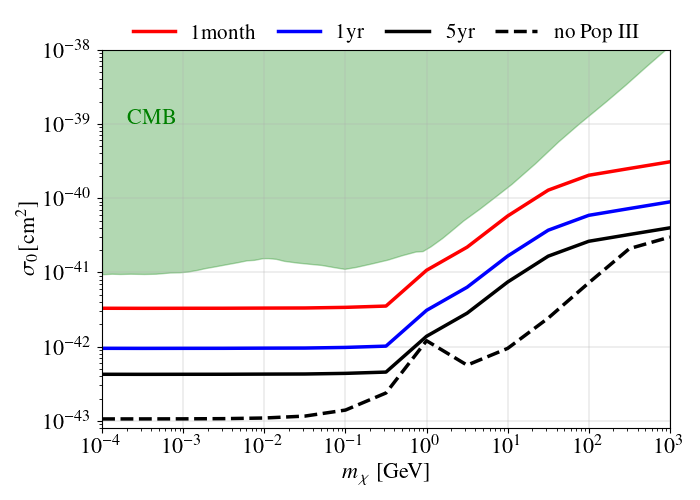

In [3]:
LineWidth = 2.5
FontSize = 16

mx = 10.0**mx_ax
data_CMB = np.load('/Users/cangtao/FileVault/GitHub/ResearchArchive/Hongmeng_SDM_2025_AA_SSPMA/data/2505.03148.Fig.6.CMB.npz')
m_CMB = 10**data_CMB['x']
s_CMB = 10**data_CMB['y']

fig, ax = plt.subplots()
ax.grid(True, which='major', linewidth = 0.3)  # `which='both'` enables major and minor grids
fig.set_size_inches(7, 5)

plt.plot(mx, sx[0,:], 'r', linewidth=LineWidth, label = '1month')
plt.plot(mx, sx[1,:], 'b', linewidth=LineWidth, label = '1yr')
plt.plot(mx, sx[2,:], 'k', linewidth=LineWidth, label = '5yr')
plt.plot(mx, sx_II[2,:], '--k', linewidth=LineWidth, label = 'no Pop III')
plt.fill_between(m_CMB, s_CMB, 1E-30, color = 'g',alpha=0.3)

plt.xlabel('$m_\chi$ [GeV]',fontsize=FontSize,fontname='Times New Roman')
plt.ylabel('$\sigma_0[{\\rm cm^2}]$',fontsize=FontSize,fontname='Times New Roman')
plt.xticks(size=FontSize)
plt.yticks(size=FontSize)
plt.xscale('log')
plt.yscale('log')
plt.text(2E-4, 1E-39, 'CMB', size=FontSize, rotation = 0, color='g')
plt.xlim([1E-4, 1E3])
plt.ylim([8E-44, 1E-38])

# plt.legend(fontsize=FontSize/1.05,loc = 'lower right', framealpha = 0, bbox_to_anchor=(1.00, 0.00), borderaxespad=0.0)
plt.legend(fontsize=FontSize/1.05,loc = 'upper center',ncol=4,framealpha = 0, bbox_to_anchor=(0.5, 1.09),columnspacing=1.0, borderaxespad=0.0)

plt.tight_layout()
plt.savefig("/Users/cangtao/Desktop/Forecast_Limits.pdf", bbox_inches = 'tight')

In [4]:
PL.show_time()

Time now: 2026-11-22 13:03
